# Stock-Level Momentum: Construction, Validation and Backtest

## Workflow and scope

1. **Freeze inputs.** Read the authorized WRDS annual CRSP snapshot (December 1925–December 2025), its trading calendar, historical classifications and delisting records. Read KF daily/monthly **value-weighted momentum deciles** independently.
2. **Form monthly portfolios.** Select common stocks on NYSE/AMEX/NASDAQ using formation-date classifications. Rank on months **t−12 through t−2**, skip t−1, apply NYSE decile cutoffs, and weight stocks by t−1 market equity. Require price at t−13, a good t−2 return, and positive t−1 market equity.
3. **Value stocks.** Set missing **ordinary** stock returns to zero under the selected valuation convention. Include known delisting returns once, following DM. Preserve unknown/partial terminal values as unknown. These missing-data choices are distinguished from published construction rules below.
4. **Build returns.** Monthly WML is monthly P10 minus P1. Within a holding month, reconstruct each leg's daily return using drifting stock values and fixed membership, then subtract the two legs. Do not compound daily WML into monthly WML.
5. **Forecast risk.** At month-end, compute $\hat\sigma=\sqrt{21\sum_{j=1}^{126}r_{WML,j}^2/126}$. Apply $(0.12/\sqrt{12})/\hat\sigma$ to the following month's monthly WML. Missing forecasts remain unknown, never cash.
6. **Evaluate identical calendars.** Show available paper-era **1927-05–2011-12** and the disjoint extension **2012–2025**. The original paper starts 1927-03; its first two risk forecasts cannot be reproduced from the available public early daily history.
7. **Report results and checks.** Retain complete KF and published-return stock-reference results, stock transaction costs, monthly reconstruction residuals, and the latest DM-aligned coverage. Withhold full-window independent-stock metrics when valuations are incomplete.

**Interpretation:** The complete stock reference uses published numeric monthly returns with numeric monthly gaps set to zero and **shared KF risk weights**. It isolates monthly WML differences but retains unconfirmed terminal values. The current DM-aligned calculation is stricter about terminal values and remains incomplete. The two are labelled throughout; a complete reference is not evidence of a complete independent replication.

Earlier notebooks and superseded experiments are archived. This notebook documents and validates the current process. Official results are produced by the ordered package pipeline, not notebook execution.

**Current formation-quality update:** require a usable period-end formation value and t−13 price. Reject LA and invalid price/date substitutes; retain valid TR/BA and NS only when the actual price date is period-end. All current monthly tables and shared-KF-risk accounts below use the new universe. Independent stock-daily inputs have been supplemented for changed memberships (10,507 additional daily rows). Strict period/special-value checks still leave no complete month-end 126-session stock-risk forecast; independent managed performance is withheld, not converted into cash. Full label meanings and field-specific policy are in `CIZ_FLAGS.md`.

**Implementation:** all current construction, valuation, daily reconstruction and risk calculations call `src/momentum_risk_project/wml_pipeline.py`. Notebook 05 can load the same versioned build and pass explicit monthly factor weights to its stock-level cost interface. Cached comparison files are validation targets, not a second implementation.

## 1. Data sources, complete processing specification and references

Read this specification before the calculations. **Provider documentation explains data definitions; the bullets marked project convention describe our implementation choices.** The current source of executable logic is `wml_pipeline.py` and its called modules; the closing API/test guide shows how to reuse and verify it. References below were checked on 2026-11-01; execution uses frozen local snapshots rather than today's web downloads.

### 1.1 Inputs, fields, dates and provenance

- **Provider/access:** CRSP supplies the observations; WRDS provides authorized access. The frozen annual schema is `crsp_a_stock`, requested from **1925-12-01 to 2025-12-31**. A matching coverage end date or CIZ format does not establish an identical release vintage to KF or the original paper. Query text, extraction dates, row counts and SHA-256 fingerprints are in each raw cache's `cache_manifest.json`.
- **Monthly stocks:** `msf_v2` supplies `permno`, `mthcaldt`, decimal total return `mthret`, ex-distribution return `mthretx`, price `mthprc`, capitalization `mthcap`, actual price date `mthprcdt`, date/price/return/delisting/completeness flags and CIZ classifications. Use the provider's capitalization field; do not silently recompute it from a possibly stale quote. `msenames` supplies historical `shrcd`/`exchcd`, joined by PERMNO and the name interval containing the observation date. Missing historical classifications are not backfilled from a current ticker. `stksecurityinfohist` and legacy `msf` extracts support diagnostics, not an alternative unlabelled production return source.
- **Daily stocks:** `dsf_v2` supplies dates, total/ex-distribution returns, prices and component/missing/duration flags (`dlycaldt`, `dlyret`, `dlyretx`, `dlyprc`, `dlyprcflg`, `dlydelflg`, `dlyretmissflg`, `dlyretdurflg`). Fetch the **formed P1/P10 stock-month universe**, without deleting securities because their holding-month status changed. Yearly source files and the supplementary membership attestation bind the cached daily requests to the actual formed universe. An absent stock-day is not declared zero merely because a different universe was downloaded.
- **Calendar/events/metadata:** `metaexchangecalendar` selects `tradingflg=Y`, `exchangegroup=CIZ`; it supplies historical trading sessions, including special closures and Saturday trading. `stkdelists` supplies the event date, recorded return and related payoff/next-price dates and amounts. `metaflaginfo` supplies field-specific flag definitions. An event, a missing quote and an exchange holiday are distinct conditions.
- **Independent benchmark:** KF `10_Portfolios_Prior_12_2` and `10_Portfolios_Prior_12_2_Daily`, **table 0, value-weighted**, are cached as `02_kf_momentum_deciles_monthly_vw.parquet` and `02_kf_momentum_deciles_daily_vw.parquet`. Validate ten ordered decile columns, date order/uniqueness and missing sentinels, then convert percent returns to decimals. This is decile WML, not the separately published 2-by-3 Mom factor. Frozen public-source version comparisons are in `03_version_audit_20261030`; current live KF availability is not used to overwrite those inputs.
- **Retained paths:** raw monthly/event bundle `data/raw/03_stock_full_20261031/`; current selected daily bundle `data/raw/03_quality_daily_20261031/`; reusable build `data/processed/wml_current/`; reports/audits `results/replication/ and results/extension/`. The compact `data/interim/reference/pre_quality/` is an old diagnostic comparator, not the current universe. Raw licensed data and credentials are not published to Git.

### 1.2 Formation universe and price-quality screen

At holding month `t`, use formation observations at `t-1`. Require observed historical share codes **10/11**, exchange codes **1/2/3**, and no already-recorded formation-month delisting (`mthdelflg=N`). Retain a stock delisted during the subsequent holding month for return/settlement processing rather than removing its loss retrospectively.

Historical legacy classifications in this cache stop at 2024. **Project adapter for January 2025 onward only:** when both historical codes are absent, require `securitytype=EQTY`, `securitysubtype=COM`, `sharetype=NS`, `usincflg=Y`, `issuertype` in `ACOR/CORP`, `primaryexch` in `N/A/Q`, `conditionaltype=RW`, `tradingstatusflg=A`. Label the mapping source on holdings and preserve the raw fields. It is not a proven identity to all historical legacy categories. Basis: [CRSP share-code crosswalk](https://www.crsp.org/wp-content/uploads/ShareCode.html) and [WRDS CIZ-to-SIZ mapping](https://wrds-www.wharton.upenn.edu/pages/wrds-research/macros/crsp-ciztosiz-macro/).

**Project formation-quality convention:** require a finite positive price, `mthprcflg` in `TR/BA`, and actual `mthprcdt == mthcaldt`, where `mthcaldt` is the provider's period-end trading date, not necessarily the last calendar day. Allow `mthdtflg=PE`, or `NS` only when the actual price date equals that period-end. Positive finite `mthcap` is also required for formation weights. Apply the corresponding price screen to the required `t-13` price. LA and other stale/beginning/missing/delisting substitutes cannot establish these endpoint values. BA is a usable bid-ask quote, not a missing-price fill. Do not automatically discard every red/yellow completeness flag or rewrite holding-month returns when screening formation prices.

### 1.3 Ranking, breakpoints and weights

[KF monthly construction](https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/Data_Library/det_10_port_form_pr_12_2.html) requires an endpoint price at `t-13`, a valid `t-2` return, permitted intermediate missing-price codes and market equity at `t-1`. Our signal uses the **11 consecutive calendar months t-12 through t-2**, skipping `t-1`. It compounds simple returns via summed `log1p`; an observed -100% return has a separate loss indicator. This use of logs calculates a ranking product, not a log portfolio-return series. Reject unexplained gaps rather than requiring all 11 returns to be numeric.

Legacy missing code -99 is allowed only as the documented intermediate missing-price case; other unexplained missing codes are ineligible. **Unverified CIZ adapter:** a missing numeric return with `mthretflg=NT`, `mthprcflg=MP`, missing price and `mthdelflg=N` is treated as the permitted missing-price case and omitted from the ranking product. The rolling calendar still needs 11 rows and the final `t-2` return must be valid. This is not a demonstrated one-to-one translation of legacy -99.

Compute NYSE 10th–90th percentile breakpoints each holding month using pandas quantiles; place each eligible stock in `1 + count(signal > breakpoint)`, so ties stay on the lower side. Require every requested month to have finite NYSE cutoffs. Within each decile, normalize **t-1 market equity** to sum to one; P10 is the winner and P1 the loser. WML factor weight one means **+1 long P10 / -1 short P1**, net zero and gross two. Breakpoint interpolation and tie handling are explicit implementation choices, not an assertion of identical KF source code.

### 1.4 Monthly valuation, ordinary gaps and delisting

Provider CIZ stock returns are decimal simple total returns; dividends are already incorporated. The [KF format notice](https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/data_library.html) distinguishes legacy FIZ month-level dividend timing from CIZ daily compounding with ex-date reinvestment. Use `mthret` rather than a raw month-end/month-start price ratio or a log return. For each decile, sum formation weights times holding-month total returns; monthly WML is **monthly P10 minus monthly P1**, not the product of daily WML gross returns.

**Two explicit policies:**

- **Strict/DM-aligned (`return_dm`):** ordinary missing numeric monthly returns are zero only when the stock is flagged active (`N`) and has no delisting event. This zero rule is a user-selected valuation assumption, not a complete KF/DM missing-return rule. Finite valid total returns must be at least -1. Any unresolved positive-weight holding invalidates the leg/month; do not drop its weight and renormalize the surviving stocks.
- **Complete reference (`return_reference`):** retain published numeric aggregate returns and set numeric gaps to zero, including unconfirmed terminal cases. This intentionally weaker reference is conditional and separately labelled; it is not an automatic fallback from the strict policy.

For [CRSP monthly delisting flags](https://www.crsp.org/wp-content/uploads/appendix/FlagType_DE.html), A/P already incorporate a terminal component; do not add it again. G/M indicate an excluded/unavailable component. When both the published pre-event return and a finite recorded `DelRet >= -1` are available for G/M, combine them once as `(1+r)*(1+DelRet)-1`. When the published total is absent, the strict current policy can use a finite recorded nonpartial event return. V is partial and remains unresolved; missing final values are not invented as -100% or zero in the strict policy. Reject duplicate delisting events per stock-month pending event-level treatment. [Daniel–Moskowitz Section 2, item 6](https://www.kentdaniel.net/data/momentum/mom_data.pdf) motivates including delisting returns; assigning known later-recorded payoffs to the event month is our research attribution convention, not proof of contemporaneous disclosure or cash availability. Do not compute a terminal payoff from a price many years later or infer delisting merely from an NT flag.

### 1.5 Daily construction and the >200-session audit

The current mode is **`zero_regular_dm_checked`**. Align each held stock to the independent CRSP calendar, fix membership and initial value weights for the month, and let total-return values drift within each leg. Same-date regular and delisting Y components compound; duplicate stock/date/component rows are rejected. Shift separate Y components to the event's corresponding session before aggregation, recover a known nonpartial missing Y payoff if recorded, and avoid adding an already represented payoff twice. Once settled, proceeds stay in cash for the rest of that month. Unknown terminal information breaks the affected value path and is not washed away by later observations.

**Project ordinary-gap rule:** missing regular components/legitimate absent ordinary rows may be zero only after universe attestation. Protect special missing-value flags: regular records outside `NA/MP/NT/GP` remain unknown. In particular, unresolved corporate-action or terminal flags are not ordinary price gaps. `P1`–`P9` duration codes span multiple sessions and cannot be read as one-day returns. `D1/D2/D3/D4/DU` represent one trading session with different calendar-day spans and are accepted. These are the current executable checks, not a claim that every possible future provider code has been resolved.

Daily leg returns are changes in full-denominator total-return values; unknown weighted stock values invalidate the leg. Subtract daily P1 from daily P10. Our daily series retains **monthly formation**, following [DM Section 3.1](https://www.kentdaniel.net/data/momentum/mom_data.pdf); [KF's daily deciles](https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/Data_Library/det_10_port_form_pr_12_2_daily.html) are formed daily. A shared label WML does not remove this difference.

The separate long-gap audit counts actual CRSP sessions since a usable daily TR/BA quote. Exclusion begins at the **201st unpriced trading session**; the restored-quote date is excluded from the interval, so a return to quoting can restore eligibility. Apply audited intervals at formation dates. This adds no otherwise-eligible monthly exclusions in the current data; it is not asserted as a rule documented by KF's momentum-decile pages. Historical carry-price sensitivities are not the current checked-daily baseline.

### 1.6 Risk, evaluation, costs and integrity checks

Use the actual final trading-day estimate of each origin month, preserving NaN rather than searching backward for an older valid estimate. [Barroso–Santa-Clara (2015), equations 5–6](https://doi.org/10.1016/j.jfineco.2014.11.010): `sigma = sqrt(21 * mean(last 126 daily WML**2))`, no demeaning; next holding-month multiplier is `(0.12/sqrt(12))/sigma`. Require all 126 observations. A missing forecast is unknown, not zero exposure or cash. The API already labels risk weights by the holding month; never add a second lag.

Reconstruct from 1927-01 with earlier raw history; evaluate **1927-05–2011-12** and **2012-01–2025-12** on matching complete calendars. The public KF daily series begins 1926-11-03, leaving insufficient warm-up for March/April 1927. The extension is post-sample, not wholly post-publication. Do not drop interior missing months then compound a stitched wealth path. Current checked own-stock risk has no complete month-end forecasts, so the complete reference uses **shared KF risk weights**; strict independent full-window managed results are withheld. Compare known paired strict monthly returns only as diagnostics, not a continuous strict account.

Notebook 03's 10bp stock-cost examples use the funded stock account: charge each dollar bought/sold, solve after-fee NAV targets, use total returns for P&L and ex-distribution returns for price drift, with monthly distribution cash and known delisting settlement. Financing is zero. Every call starts from cash; Notebook 03 evaluates separate episodes, whereas Notebook 05 runs once then slices for continuous-window costs. Neither identifies borrow/rebates, market capacity or actual delayed cash dates. Paper Appendix B half-turnover and its inverse-L/scaled-L ambiguity are examined in Notebook 05, not silently equated to this account's full absolute traded amount.

Validate date uniqueness/consecutive calendars, positive normalized leg weights, formation-before-holding, classification/ranking endpoints, known-payoff-once identities, no-future-data risk influence, artifact/source/universe fingerprints, exact saved-return agreement, fees/trade aggregation, and missing-risk coverage. The output manifest records parameters and code/input hashes. Full flag meanings and implementation references are in [CIZ_FLAGS.md](../CIZ_FLAGS.md) and [WML_PIPELINE.md](../WML_PIPELINE.md); the frozen dictionary has **774 codes across 62 field-specific types**. A code's meaning depends on its field, not its letters alone.

### 1.7 Official reference index and flag dictionary

- KF: [monthly momentum deciles](https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/Data_Library/det_10_port_form_pr_12_2.html), [daily momentum deciles](https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/Data_Library/det_10_port_form_pr_12_2_daily.html), [CIZ/FIZ format and dividend timing](https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/data_library.html).
- CRSP field definitions: [AG date flags](https://www.crsp.org/wp-content/uploads/appendix/FlagType_AG.html) (`mthdtflg` versus previous-date fields), [PC prices](https://www.crsp.org/wp-content/uploads/appendix/FlagType_PC.html), [AR aggregate returns](https://www.crsp.org/wp-content/uploads/appendix/FlagType_AR.html), [DE monthly terminal status](https://www.crsp.org/wp-content/uploads/appendix/FlagType_DE.html), [RM daily missing causes](https://www.crsp.org/wp-content/uploads/appendix/FlagType_RM.html), [RD duration](https://www.crsp.org/wp-content/uploads/appendix/FlagType_RD.html), [CF completeness](https://www.crsp.org/wp-content/uploads/appendix/FlagType_CF.html), [CG completeness subflags](https://www.crsp.org/wp-content/uploads/appendix/FlagType_CG.html).
- Classifications: [CRSP share-code crosswalk](https://www.crsp.org/wp-content/uploads/ShareCode.html), [WRDS CIZ-to-SIZ macro](https://wrds-www.wharton.upenn.edu/pages/wrds-research/macros/crsp-ciztosiz-macro/). The latter documents mapping fields; it does not certify this frozen cache's exact release equivalence to KF.
- Research methods: [DM portfolio/data notes](https://www.kentdaniel.net/data/momentum/mom_data.pdf), [Barroso–Santa-Clara paper](https://doi.org/10.1016/j.jfineco.2014.11.010). These are the authors' research references, distinct from provider data dictionaries. None of these links is cited as authority for our ordinary-zero or late-payoff attribution assumptions.


In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
from IPython.display import display, Image
from momentum_risk_project.paths import project_root
from momentum_risk_project.config import load_config, configured_path, config_digest

ROOT = project_root()
CONFIG = load_config(root=ROOT)
RESULTS = configured_path(CONFIG, "results", ROOT)
STUDY = configured_path(CONFIG, "study", ROOT)
BUILD_PATH = configured_path(CONFIG, "build", ROOT)
HIST = RESULTS / "replication/tables/paper_available_common"
if not (HIST / "run.json").exists():
    raise FileNotFoundError("Generate official results first: python run_all.py")
assert __import__("json").loads((HIST / "run.json").read_text())["config_digest"] == config_digest(CONFIG)


## 2. Restore the current package build and audit its lineage

Stage 02 selects/validates fields into `data/interim/stock_inputs`, then calls the existing construction and checked-daily API. It writes the analysis-ready artifact with source fingerprints. Raw SQL download bundles are unchanged. A metadata inventory records the historical 774-code dictionary; the current configuration identifies each source path.

In [2]:
import json
from momentum_risk_project.wml_pipeline import load_build, estimate_risk
from momentum_risk_project.data import clean_momentum
build = load_build(BUILD_PATH)
display(pd.Series(build.audit,name="Audit").to_frame())
np.testing.assert_allclose(build.holdings.groupby(["month","momentum_decile"]).leg_weight.sum(),1.)
assert (build.holdings.formation_month + 1).equals(build.holdings.month)
print("Verified analysis-ready artifact:",CONFIG["paths"]["build"])
print("Intermediate staging:",CONFIG["paths"]["stock_inputs"])


,Audit
formation_candidates,3838254
formation_candidates_in_price_gap,9565
formation_price_gap_exclusions,0
eligible_stock_months,3493938
ciz_fallback_eligible_stock_months,39352
admitted_with_missing_price_history,4200
missing_numeric_wml_stock_months,66
formation_policy,period-end TR/BA; NS only on actual period-end...
monthly_policy,ordinary gaps zero; known DM payoff once; unkn...
reference_policy,"published numeric monthly returns, numeric gap..."


Verified analysis-ready artifact: data/processed/wml_current
Intermediate staging: data/interim/stock_inputs


## 3. Reported reconstruction errors and risk coverage

These tables are generated by package evaluation/study functions, not by reusing an older output as an input. Published-reference error is a complete-series diagnostic; strict paired errors are not a continuous wealth estimate. The checked own-stock risk coverage remains explicit. Unknown terminal returns and risk forecasts are not cash.

In [3]:
for scope,window in [("replication","paper_available_common"),("extension","extension_disjoint")]:
    folder=RESULTS/scope/"tables"/window
    print(f"Reference reconstruction errors: {window}")
    display(pd.read_csv(folder/"reference_reconstruction_errors.csv"))
    print(f"Strict known-pair errors: {window}")
    display(pd.read_csv(folder/"strict_paired_reconstruction_errors.csv"))
print("Continuous strict-account and own-risk coverage")
display(pd.read_csv(STUDY/"coverage.csv"))


Reference reconstruction errors: paper_available_common


,window,calendar_months,known_paired_months,correlation,MAE_bps,RMSE_bps
0,paper_available_common,1016,1016,0.99915,13.90597,32.705354


Strict known-pair errors: paper_available_common


,window,calendar_months,known_paired_months,correlation,MAE_bps,RMSE_bps
0,paper_available_common,1016,566,0.998689,14.833871,38.1256


Reference reconstruction errors: extension_disjoint


,window,calendar_months,known_paired_months,correlation,MAE_bps,RMSE_bps
0,extension_disjoint,168,168,0.994141,47.434354,84.778615


Strict known-pair errors: extension_disjoint


,window,calendar_months,known_paired_months,correlation,MAE_bps,RMSE_bps
0,extension_disjoint,168,109,0.996147,38.455004,70.297977


Continuous strict-account and own-risk coverage


,window,start,end,months,own_stock_risk_forecasts,strict_DM_monthly_returns,strict_continuous_account_known_months,cash_fill_used
0,paper_available_common,1927-05,2011-12,1016,0,566,35,False
1,paper_turnover_test,1951-03,2010-12,718,0,311,0,False
2,extension_disjoint,2012-01,2025-12,168,0,109,0,False


## 4. Formation-price example and saved-return agreement

August 1935 illustrates the stale-quote problem discussed in the source specification. The current endpoint screen is general, not an exclusion chosen for one company. The untouched earlier audit remains in private intermediate history. The following checks the current result directly from the packaged build and frozen KF input.

In [4]:
kf_monthly = clean_momentum(pd.read_parquet(configured_path(CONFIG,"kf_monthly",ROOT)),"monthly").mom
print("August 1935 current screened monthly WML and independent KF benchmark")
display(pd.DataFrame({"Rebuilt reference":build.monthly_reference.WML,"KF":kf_monthly}).loc[[pd.Period("1935-08")]])
reported=pd.read_csv(HIST/"rebuilt_KF_returns.csv",index_col=0)
reported.index=pd.PeriodIndex(reported.index,freq="M")
np.testing.assert_allclose(reported.rebuilt_reference_unmanaged,build.monthly_reference.WML.reindex(reported.index))
assert np.isclose(build.monthly_reference.WML.loc["1935-08"],-.18323,atol=1e-5)
print("Current source build matches the scripted historical return report.")


August 1935 current screened monthly WML and independent KF benchmark


,Rebuilt reference,KF
month,,
1935-08,-0.18323,-0.1832


Current source build matches the scripted historical return report.


## 5. Gross/net results generated outside this notebook

The package uses common KF risk weights for the complete published-reference comparison. The reference retains terminal uncertainty. Strict independent stock-risk managed performance is withheld. Notebook 05 explains continuous stock-cost accounting; the current pipeline runs one continuous stock study then slices its evaluation windows.

Complete reference stock-cost metrics: 10bp per actual dollar traded, financing zero


,window,strategy,method,cost_bps_per_dollar,Annualized Mean Return,Annualized Volatility,Sharpe (rf=0),CAGR,Maximum Drawdown,Terminal Wealth,Worst month,Skewness,Excess kurtosis,Mean absolute traded notional,Annual trading cost
36,paper_available_common,unmanaged,funded_account,10.0,0.130049,0.274467,0.473824,0.085897,-0.962250,1071.758178,-0.782602,-2.427533,18.393689,1.536254,0.018435
37,paper_turnover_test,unmanaged,funded_account,10.0,0.143241,0.227033,0.630928,0.121540,-0.817615,956.288483,-0.451955,-1.553690,8.898364,1.445879,0.017351
38,extension_disjoint,unmanaged,funded_account,10.0,0.028366,0.271180,0.104604,-0.010253,-0.641382,0.865639,-0.296577,-0.856670,2.137287,1.490802,0.017890
81,paper_available_common,managed_shared_KF_risk,funded_account,10.0,0.150658,0.167359,0.900212,0.145487,-0.439088,98744.011592,-0.247758,-0.367106,2.128254,1.352080,0.016225
82,paper_turnover_test,managed_shared_KF_risk,funded_account,10.0,0.179342,0.170448,1.052177,0.177964,-0.300873,18033.189811,-0.169973,-0.164772,1.172358,1.463262,0.017559
83,extension_disjoint,managed_shared_KF_risk,funded_account,10.0,0.032156,0.119203,0.269756,0.025393,-0.225427,1.420586,-0.115830,0.029410,1.001317,0.753308,0.009040


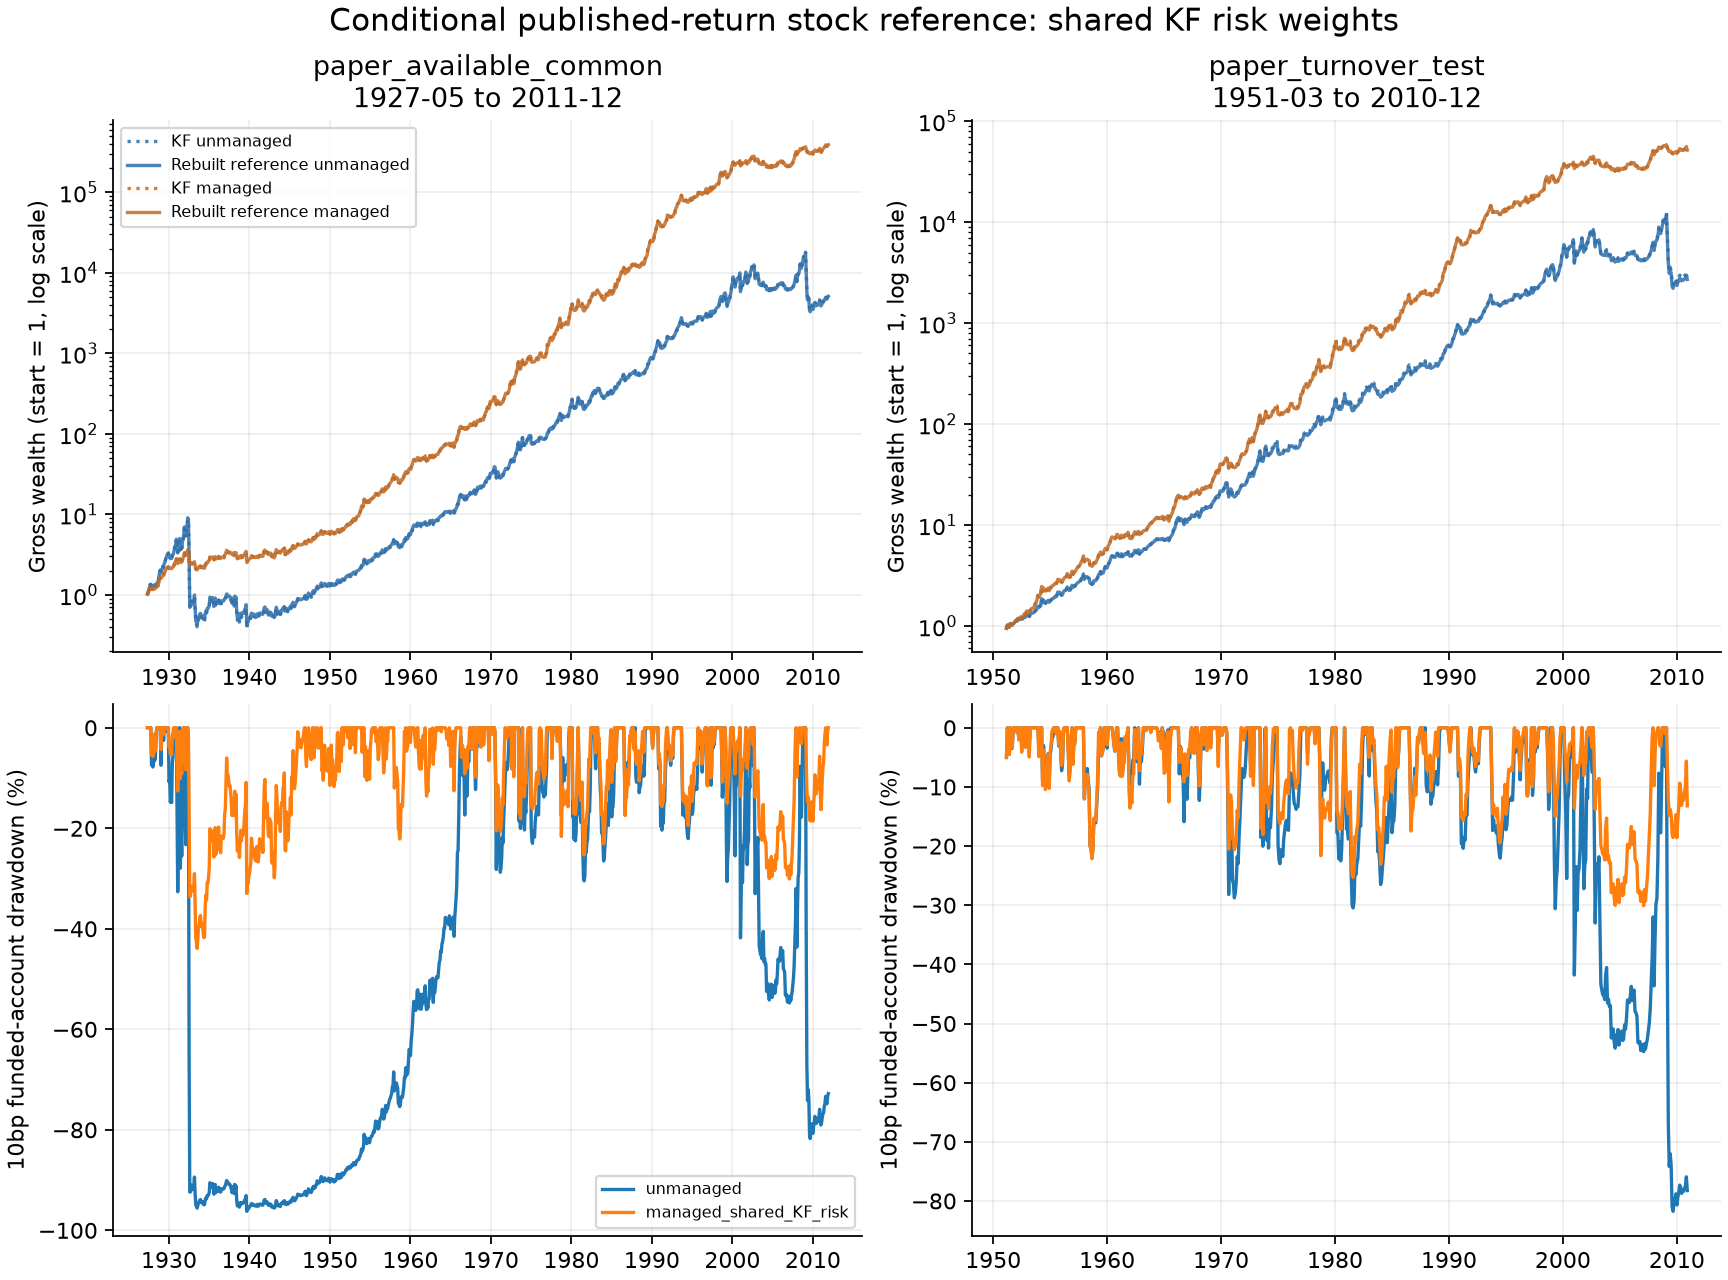

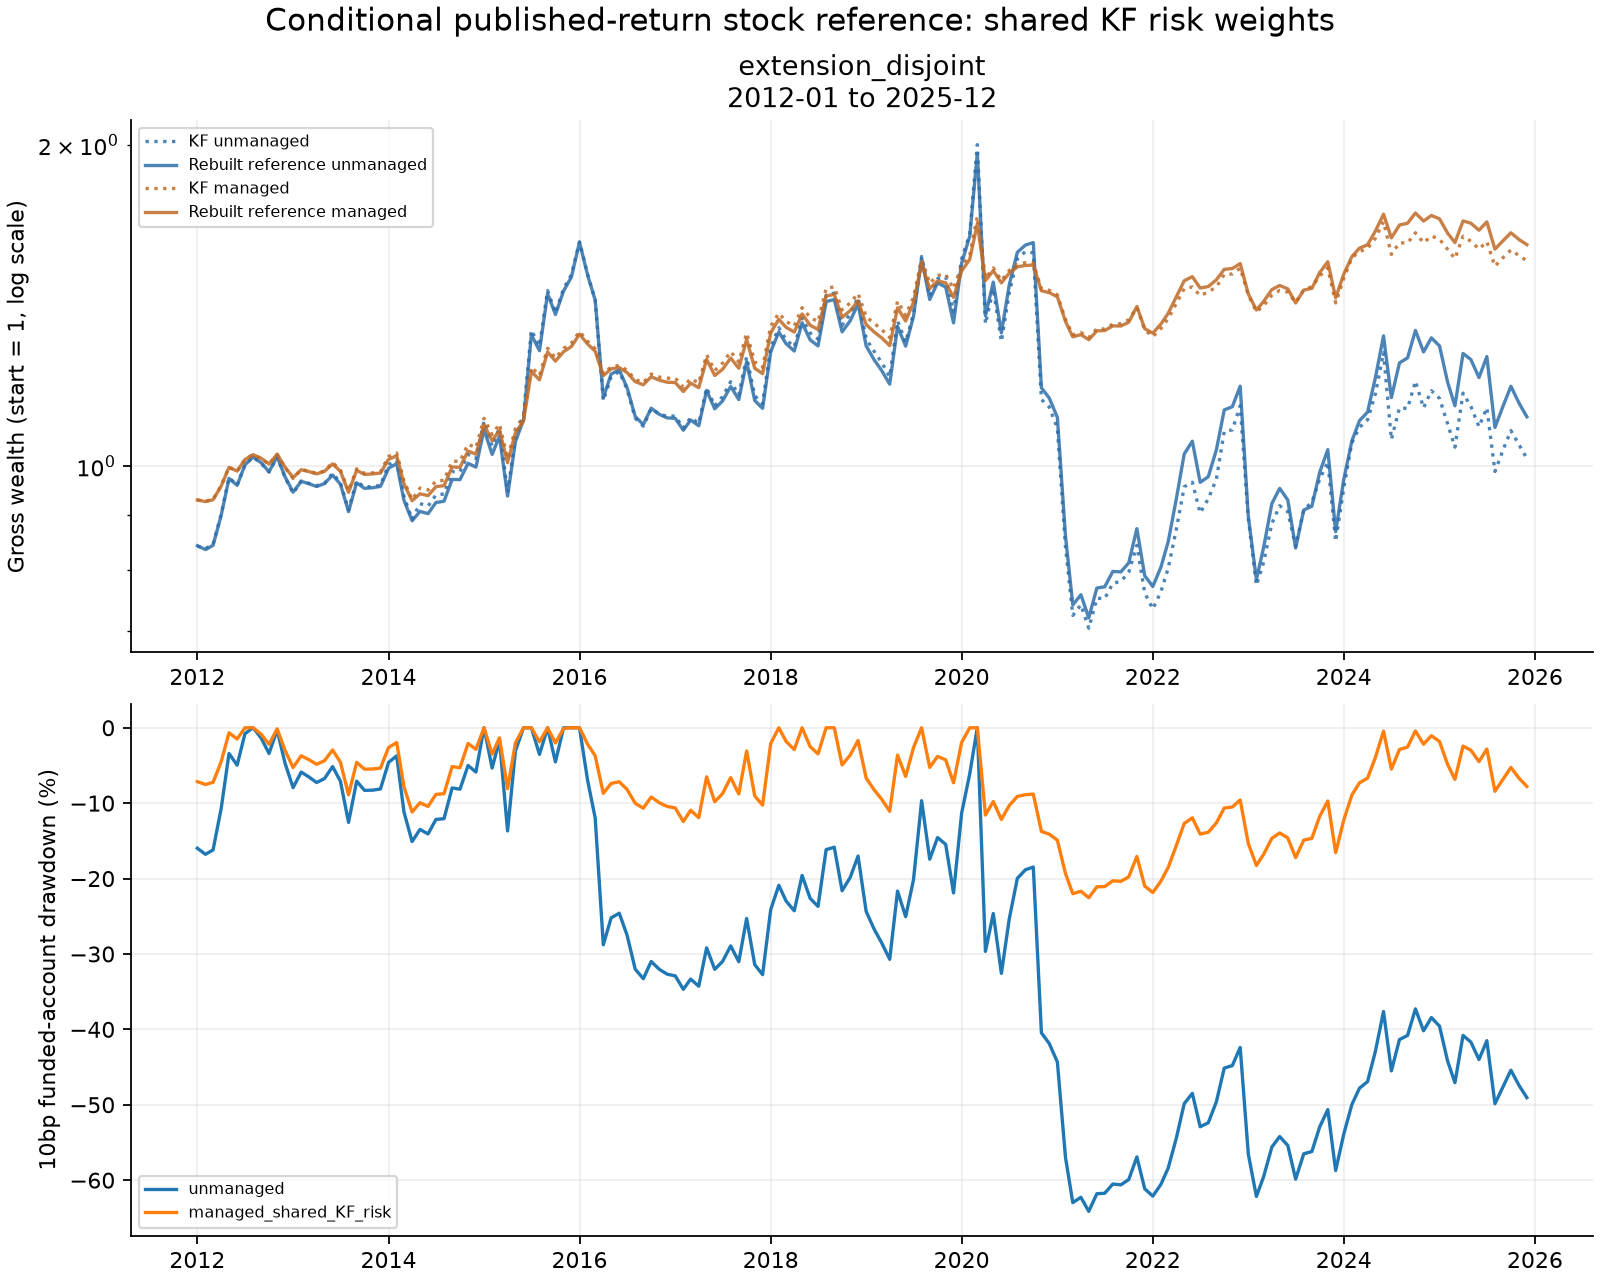

In [5]:
print("Complete reference stock-cost metrics: 10bp per actual dollar traded, financing zero")
metrics=pd.read_csv(STUDY/"metrics.csv")
display(metrics.loc[metrics.method.eq("funded_account") & metrics.cost_bps_per_dollar.eq(10)])
for scope in ["replication","extension"]:
    display(Image(filename=str(RESULTS/scope/"figures/stock_costs/wealth_and_drawdown.png")))


## 6. Packaged API calls and reproduction

Run `python scripts/01_get_data.py`, `02_build_dataset.py`, `03_replicate.py`, `04_extend.py` in order, or `python run_all.py`. All source/data/results paths and scientific settings come from `configs/config.yaml`. No notebook is needed to regenerate results.

`build_from_cache(staged_cache, start=..., end=...)` builds monthly portfolios; `rebuild_daily(build, daily_cache)` verifies the requested universe and adds checked daily returns; `save_build(build, new_directory)` refuses an existing directory. The orchestrator archives a superseded processed build instead of modifying raw history. `load_build` restores/validates it. `estimate_risk` returns already lagged holding-month weights. `build.targets` returns signed stock targets; `build.backtest` requires an explicit valuation policy. Do not add another lag, silently fill missing forecasts, or substitute the factor-proxy cost model for stock costs.

In [6]:
api_months=pd.period_range("2012-01","2025-12",freq="M")
api_daily=clean_momentum(pd.read_parquet(configured_path(CONFIG,"kf_daily",ROOT)),"daily").mom
api_shared=estimate_risk(api_daily,api_months)
api_own=estimate_risk(build.daily.WML,api_months)
assert api_shared.forecast_available.all()
api_targets=build.targets(pd.Series(1.,index=pd.period_range("2009-02",periods=1,freq="M")))
np.testing.assert_allclose(api_targets.signed_weight.abs().sum(),2.)
np.testing.assert_allclose(api_targets.signed_weight.sum(),0.,atol=1e-12)
print("Shared risk forecasts:",int(api_shared.forecast_available.sum()))
print("Strict own-risk forecasts:",int(api_own.forecast_available.sum()),"(unknown, not cash)")
display(api_targets.groupby("momentum_decile").agg(stocks=("permno","size"),signed_notional=("signed_weight","sum")))


Shared risk forecasts: 168
Strict own-risk forecasts: 0 (unknown, not cash)


,stocks,signed_notional
momentum_decile,,
1,689,-1.0
10,468,1.0


## Package tests and notebook validation

Run these commands **in a terminal from the repository root**, using the project environment. The focused suite covers current construction API, CIZ screens, ranking, delisting/daily valuation and acquisition planning:

```bash
uv run pytest -p no:cacheprovider tests/test_wml_pipeline.py tests/test_ciz_quality.py tests/test_ranking.py tests/test_stock_reconstruction.py tests/test_daily_portfolio.py tests/test_wrds_stock.py -q
```

Run the complete existing suite before integration:

```bash
uv run pytest -p no:cacheprovider tests/ -q
uv run pytest tests/test_pipeline.py -q
```

Unit tests use synthetic/local fixtures and do not require WRDS credentials or live market-data downloads. They validate implementation behavior; they do not establish equivalence to a particular CRSP/KF vintage or resolve missing economic payoffs. The executed API examples above additionally validate the shown notebook/data comparisons and require their documented local inputs. These checks are distinct from executing the entire notebook on the full research sample. If parameters, source inputs or valuation conventions change, rerun the relevant notebook and its comparisons as well as the tests. Planned EWMA/GARCH files and tests are not part of these implemented commands.